In [1]:
import numpy as np
import math
import pandas as pd
from data import fetch_dataset
import plotly.graph_objs as go
from plotly.offline import init_notebook_mode
import matplotlib.pyplot as plt
import plotly.express as px
from matplotlib.ticker import FuncFormatter
from matplotlib.dates import DateFormatter

init_notebook_mode(connected=True)
np.set_printoptions(suppress=True, floatmode='fixed')

# Import variables

In [2]:
clients = list(range(20, 100, 10))
# Initialize lists to store the last value of each file
poc_smape_last = []
selection_smape_last = []
avg_smape_last = []

poc_rmse_last = []
selection_rmse_last = []
avg_rmse_last = []

poc_mae_last = []
selection_mae_last = []
avg_mae_last = []

poc_loss_last = []
selection_loss_last = []
avg_loss_last = []

In [3]:
# Load the .npy files and extract the last value ([-1]) from each
for C in clients:
    poc_smape_last.append(np.load(f'metrics/poc_smape_C{C}.npy')[-1])
    selection_smape_last.append(np.load(f'metrics/selection_smape_C{C}.npy')[-1])
    avg_smape_last.append(np.load(f'metrics/fedavg_smape_C{C}.npy')[-1])

    poc_rmse_last.append(np.load(f'metrics/poc_rmse_C{C}.npy')[-1])
    selection_rmse_last.append(np.load(f'metrics/selection_rmse_C{C}.npy')[-1])
    avg_rmse_last.append(np.load(f'metrics/fedavg_rmse_C{C}.npy')[-1])

    poc_mae_last.append(np.load(f'metrics/poc_mae_C{C}.npy')[-1])
    selection_mae_last.append(np.load(f'metrics/selection_mae_C{C}.npy')[-1])
    avg_mae_last.append(np.load(f'metrics/fedavg_mae_C{C}.npy')[-1])

    poc_loss_last.append(np.load(f'metrics/poc_loss_C{C}.npy')[-1])
    selection_loss_last.append(np.load(f'metrics/selection_loss_C{C}.npy')[-1])
    avg_loss_last.append(np.load(f'metrics/fedavg_loss_C{C}.npy')[-1])

    

In [4]:
def comparison(poc, avg, selection, metric):
    bar_width = 0.25
    x = np.arange(len(clients))
    fig = plt.figure(figsize=(10, 9))  # Specify figure size
    
    fig_width, fig_height = fig.get_size_inches()

    font_size = min(fig_width, fig_height) * 1.5 
    tick_size = font_size * 2  
    legend_size = font_size * 1.5  
    
    # Plot bars
    plt.bar(x - bar_width, avg, width=bar_width, label='FedCSA', color='b')
    plt.bar(x, selection, width=bar_width, label='SMA', color='g')
    plt.bar(x + bar_width, poc, width=bar_width, label='POC', color='brown')
    
    plt.xlabel('Total Number of Clients', fontsize=tick_size)
    plt.ylabel(metric, fontsize=tick_size)
    
    plt.xticks(x, clients, fontsize=tick_size)
    plt.yticks(fontsize=tick_size)
    
    plt.legend(fontsize=legend_size)
    
    # Show plot
    plt.tight_layout()
    plt.show()

## SMAPE

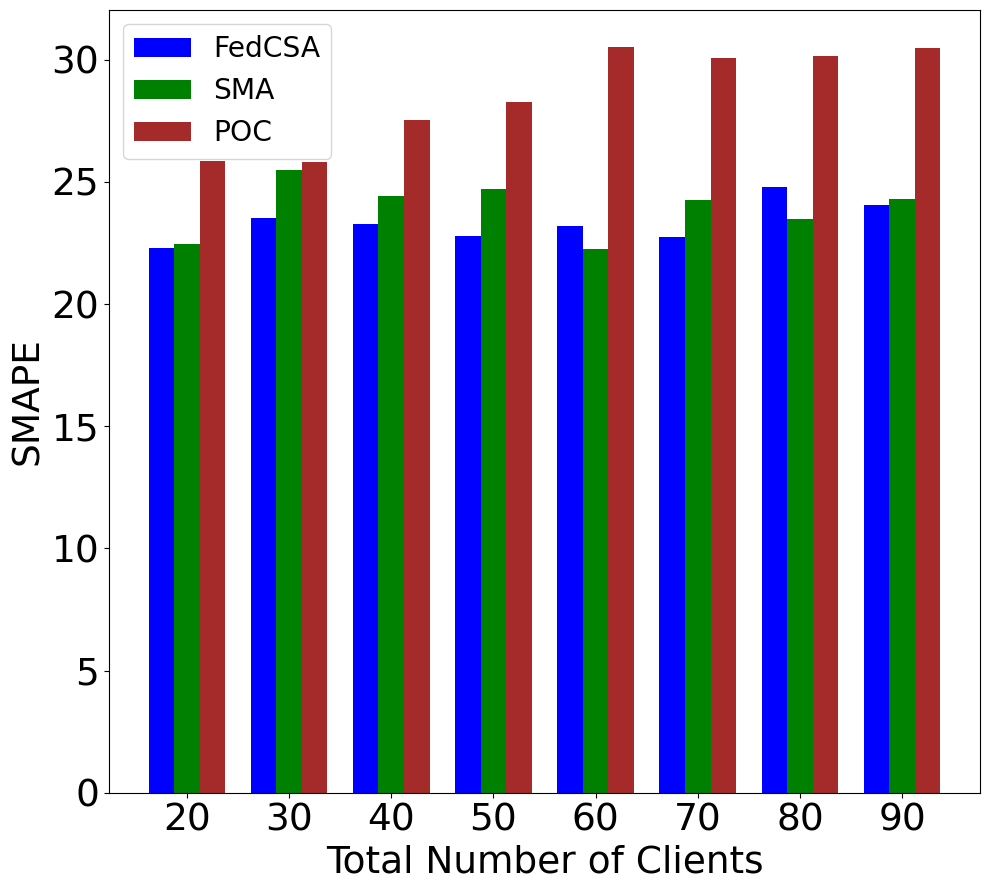

In [21]:
comparison (poc_smape_last,avg_smape_last,selection_smape_last, "SMAPE")

In [6]:
avg_smape_last,selection_smape_last,poc_smape_last

([23.303061976847214,
  23.523240988118143,
  23.28410617087999,
  22.77043773820017,
  23.190240583676083,
  22.76519063769916,
  24.784088478527888,
  24.05539016028936],
 [22.443236973636875,
  25.48905064501505,
  24.419320871401286,
  24.730216797427055,
  22.247929435650672,
  24.281312603487937,
  23.463200163972285,
  21.309012599587703],
 [25.837820067186193,
  25.83389885434509,
  27.55044460052397,
  28.27177355235652,
  30.51252638816869,
  30.088731635353682,
  30.15544432739845,
  30.46576219394423])

## RMSE

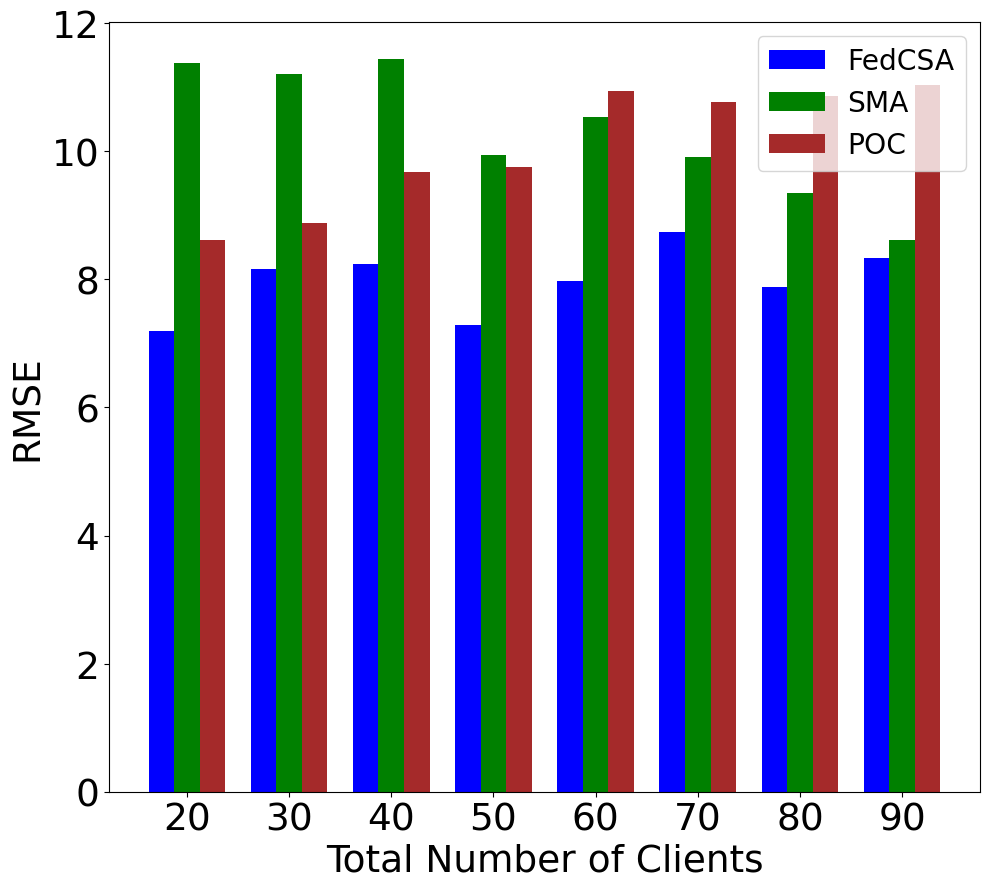

In [7]:
comparison (poc_rmse_last,avg_rmse_last,selection_rmse_last, "RMSE")

In [8]:
avg_rmse_last,selection_rmse_last,poc_rmse_last

([7.1918858707644455,
  8.158044711828472,
  8.237247642021885,
  7.2801818598536885,
  7.968085923331406,
  8.744214197068876,
  7.880250529262393,
  8.326232627110949],
 [11.37620891491859,
  11.20171940350582,
  11.446275626105209,
  9.948447906781208,
  10.531147556278484,
  9.902014682060114,
  9.35105117153563,
  8.61135771043879],
 [8.616277767511944,
  8.878060023899847,
  9.668893514205147,
  9.759655289898408,
  10.942247359844137,
  10.764805140713008,
  10.868867704994226,
  11.03357873025487])

## MAE

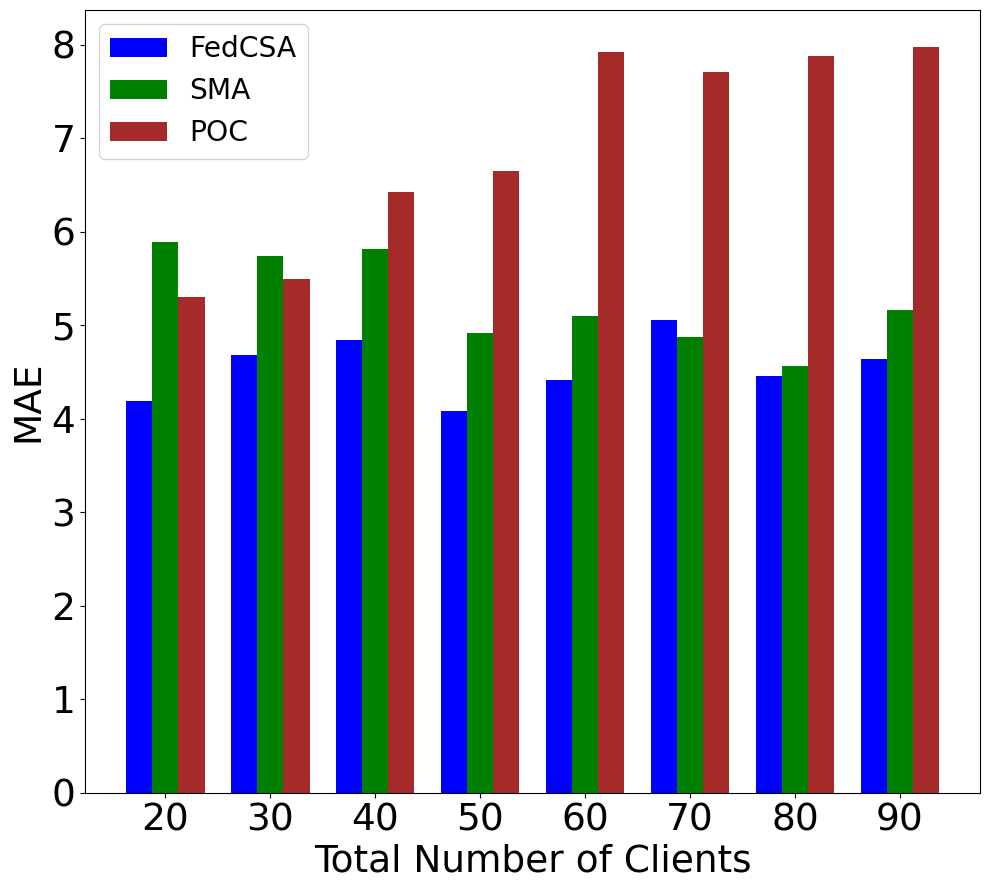

In [23]:
comparison (poc_mae_last,avg_mae_last,selection_mae_last, "MAE")

In [10]:
avg_mae_last,selection_mae_last,poc_mae_last

([4.193874522748242,
  4.68059943892691,
  4.846132036792206,
  4.086229604345381,
  4.414640886222583,
  5.056902927896612,
  4.4624001804680775,
  4.642316872102381],
 [5.891428416933385,
  5.742746763783615,
  5.820005912118559,
  4.918762198886494,
  5.09690841279448,
  4.8752998723542085,
  4.562702617951725,
  4.168752988377557],
 [5.301886016733392,
  5.490527401365255,
  6.425057747666261,
  6.647030497040044,
  7.918603196114265,
  7.708193679671327,
  7.878152117292562,
  7.973766512744058])

## Loss

In [11]:
# Initialize arrays to store all rounds for each technique
poc_all_clients = []
selection_all_clients = []
avg_all_clients = []

# Load the .npy files for each client and technique, and store the values
for C in clients:
    poc_all_clients.append(np.load(f'metrics/poc_loss_C{C}.npy'))  # Shape: (100,)
    selection_all_clients.append(np.load(f'metrics/selection_loss_C{C}.npy'))  # Shape: (100,)
    avg_all_clients.append(np.load(f'metrics/fedavg_loss_C{C}.npy'))  # Shape: (100,)

# Convert the lists to numpy arrays to facilitate averaging
poc_all_clients = np.array(poc_all_clients)  # Shape: (number of clients, 100)
selection_all_clients = np.array(selection_all_clients)  # Shape: (number of clients, 100)
avg_all_clients = np.array(avg_all_clients)  # Shape: (number of clients, 100)

# Calculate the mean across all clients for each technique
poc_avg = poc_all_clients.mean(axis=0)  # Shape: (100,)
selection_avg = selection_all_clients.mean(axis=0)  # Shape: (100,)
avg_avg = avg_all_clients.mean(axis=0)  # Shape: (100,)


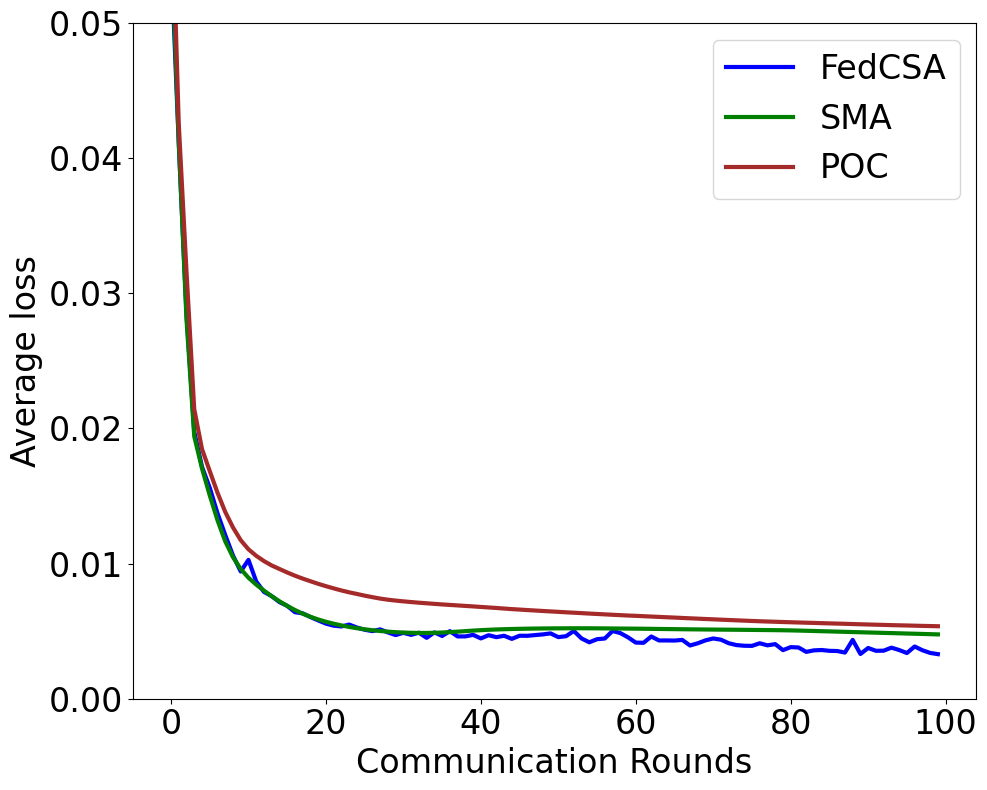

In [13]:
fig = plt.figure(figsize=(10, 8))  # Specify figure size

fig_width, fig_height = fig.get_size_inches()
font_size = min(fig_width, fig_height) * 1.5 
tick_size = font_size * 2  
legend_size = font_size * 2 
sz=2.5
# Plot each averaged technique
plt.plot(avg_avg, label='FedCSA', color='b', linewidth=3)
plt.plot(selection_avg, label='SMA', color='g', linewidth=3)
plt.plot(poc_avg, label='POC', color='brown', linewidth=3)

# Labeling the plot
plt.xlabel('Communication Rounds', fontsize=tick_size)
plt.ylabel('Average loss', fontsize=tick_size)
# plt.title('Average loss per Communication Round for Different Techniques', fontsize=16)

plt.xticks(fontsize=tick_size)
plt.yticks(fontsize=tick_size)
plt.legend(fontsize=legend_size)
plt.ylim(0,0.05)

# Show plot
plt.tight_layout()
plt.show()


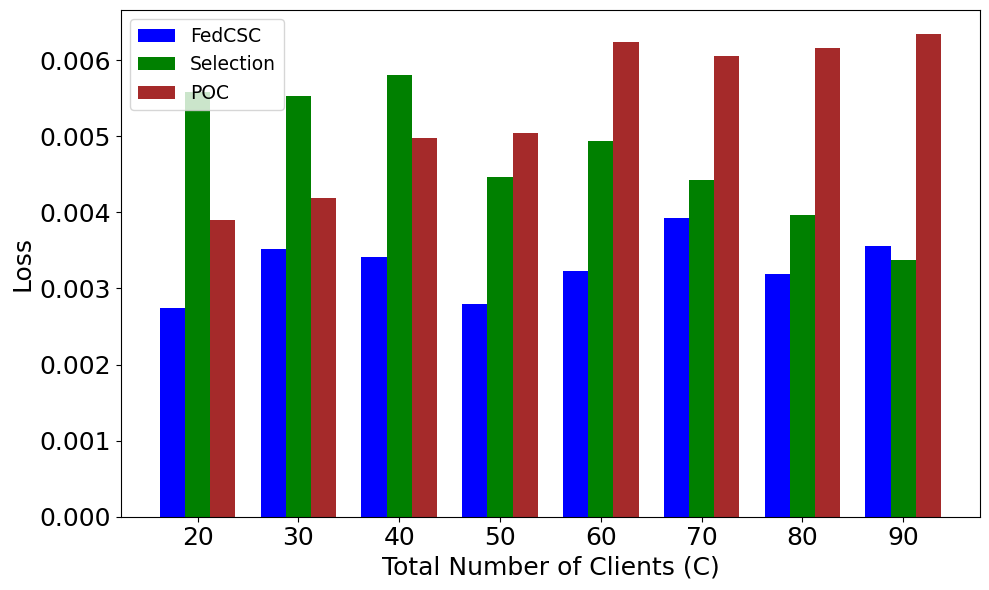

In [18]:
comparison (poc_loss_last,avg_loss_last,selection_loss_last, "Loss")

In [8]:
avg_loss_last,selection_loss_last,poc_loss_last,

([0.002746353276351102,
  0.003522839021062816,
  0.0034127504566872848,
  0.0027950166705925684,
  0.0032361180369550155,
  0.003924385821667483,
  0.0031866628803505063,
  0.0035616777166110492],
 [0.005583884175386812,
  0.005529843308899981,
  0.00580761174662585,
  0.0044612114620209645,
  0.004943088431799646,
  0.004420056884885521,
  0.00396558508845088,
  0.00336873895958382],
 [0.0039045508381225077,
  0.0041874658818534,
  0.0049777604232693114,
  0.005039308080178609,
  0.0062398828617068235,
  0.006059333787897044,
  0.006154809878446026,
  0.006343358125396927])

# visualize predicted vs actual

In [69]:
dataframes = fetch_dataset("./")

Floor1
Floor1_p8


## training floor0 with poc and FedAvg 30 and 40 clients

In [ ]:
# Loop through the keys in the 'dataframes' dictionary
i=0
name = 'Floor1_p8'
fig = go.Figure()
fig.update_layout(width=1000, height=700)

timestamps = dataframes[name].index
energy_consumption = dataframes[name]['total_demand'].values

fig.add_trace(go.Scatter(x=timestamps[-len(outputs_poc_c20[0]):], y=outputs_poc_c20[0], line=dict(color='yellow'), name=f"poc C=20"))
fig.add_trace(go.Scatter(x=timestamps[-len(outputs_selection_c20[0]):], y=outputs_selection_c20[0], line=dict(color='green'), name=f"selection C=20"))
fig.add_trace(go.Scatter(x=timestamps[-len(outputs_avg_c20[0]):], y=outputs_avg_c20[0], line=dict(color='red'), name=f"Our method C=20"))

name = 'Floor1'
timestamps = dataframes[name].index
energy_consumption = dataframes[name]['total_demand'].values
fig.add_trace(go.Scatter(x=timestamps[-len(outputs_avg_c20[0]):], y=energy_consumption[-len(outputs_avg_c20[0]):], line=dict(color='blue'), name= f"Actual values"))

fig.update_layout(
    xaxis_title="Date",
    yaxis_title="Energy Consumption (kW)",
    xaxis=dict(
        title_font=dict(size=24, color='black'),  # Adjust the font size and color of x-axis title
        tickfont=dict(size=20, color='black'),  # Adjust the font size and color of x-axis tick labels
        tickformat='%H:%M',  # Specify the time format
    ),
    yaxis=dict(
        title_font=dict(size=24, color='black'),  # Adjust the font size and color of y-axis title
        tickfont=dict(size=20, color='black')  # Adjust the font size and color of y-axis tick labels
    ),
    legend_title_font=dict(size=20, color='black'),  # Adjust the font size and color of legend title
    legend_font=dict(size=21, color='black'),  # Adjust the font size and color of legend items
    legend=dict(
        x=0.7,  # Adjust the x-coordinate of the legend (0.5 means centered)
        y=1,  # Adjust the y-coordinate of the legend (negative values move it inside the graph)
    )
)
fig.update_layout(showlegend=True)

fig.show()

In [ ]:
# # Loop through the keys in the 'dataframes' dictionary
# i=0
# name = 'Floor1_p8'
# fig = go.Figure()
# fig.update_layout(width=1000, height=700)

# timestamps = dataframes[name].index
# energy_consumption = dataframes[name]['total_demand'].values


# fig.add_trace(go.Scatter(x=timestamps[-len(outputs_poc_c30[0]):], y=outputs_poc_c30[0], line=dict(color='red'), name=f"poc C=30"))
# fig.add_trace(go.Scatter(x=timestamps[-len(outputs_selection_c30[0]):], y=outputs_selection_c30[0], line=dict(color='green'), name=f"selection C=30"))
# fig.add_trace(go.Scatter(x=timestamps[-len(outputs_avg_c30[0]):], y=outputs_avg_c30[0], line=dict(color='yellow'), name=f"Our method C=30"))


# name = 'Floor1'
# timestamps = dataframes[name].index
# energy_consumption = dataframes[name]['total_demand'].values
# fig.add_trace(go.Scatter(x=timestamps[-len(outputs_lbs_c30[0]):], y=energy_consumption[-len(outputs_lbs_c30[0]):], line=dict(color='blue'), name= f"Actual values"))

# fig.update_layout(
#     xaxis_title="Date",
#     yaxis_title="Energy Consumption (kW)",
#     xaxis=dict(
#         title_font=dict(size=24, color='black'),  # Adjust the font size and color of x-axis title
#         tickfont=dict(size=20, color='black'),  # Adjust the font size and color of x-axis tick labels
#         tickformat='%H:%M',  # Specify the time format
#     ),
#     yaxis=dict(
#         title_font=dict(size=24, color='black'),  # Adjust the font size and color of y-axis title
#         tickfont=dict(size=20, color='black')  # Adjust the font size and color of y-axis tick labels
#     ),
#     legend_title_font=dict(size=20, color='black'),  # Adjust the font size and color of legend title
#     legend_font=dict(size=21, color='black'),  # Adjust the font size and color of legend items
#     legend=dict(
#         x=0.7,  # Adjust the x-coordinate of the legend (0.5 means centered)
#         y=1,  # Adjust the y-coordinate of the legend (negative values move it inside the graph)
#     )
# )
# fig.update_layout(showlegend=True)

# fig.show()

In [ ]:
# # Loop through the keys in the 'dataframes' dictionary
# i=0
# name = 'Floor0_p4'
# fig = go.Figure()
# fig.update_layout(width=1000, height=700)

# timestamps = dataframes[name].index
# energy_consumption = dataframes[name]['total_demand'].values

# # fig.add_trace(go.Scatter(x=timestamps[-len(outputs_lbs_s3_c20[0]):], y=outputs_lbs_s3_c20[0], line=dict(color='brown'), name=f"poc C=30 using EIF-FL"))
# # fig.add_trace(go.Scatter(x=timestamps[-len(outputs_avg_c20[0]):], y=outputs_avg_c20[0]*1.06, line=dict(color='orange'), name=f"Our method C=30 using EIF-FL"))

# # fig.add_trace(go.Scatter(x=timestamps[-len(outputs_lbs_s3_c20_n5[20]):], y=outputs_lbs_s3_c20_n5[20], line=dict(color='green'), name=f"poc C=30 without EIF-FL"))
# # fig.add_trace(go.Scatter(x=timestamps[-len(outputs_avg_c20_n5[20]):], y=outputs_avg_c20_n5[20], line=dict(color='olive'), name=f"Our method C=30 without EIF-FL"))

# fig.add_trace(go.Scatter(x=timestamps[-len(outputs_lbs_s3_c40[0]):], y=outputs_lbs_s3_c40[0], line=dict(color='red'), name=f"poc C=40 using EIF-FL"))
# fig.add_trace(go.Scatter(x=timestamps[-len(outputs_avg_c40[0]):], y=outputs_avg_c40[0]*1.08, line=dict(color='orange'), name=f"Our method C=40 using EIF-FL"))

# fig.add_trace(go.Scatter(x=timestamps[-len(outputs_lbs_s3_c40_n5[0]):], y=outputs_lbs_s3_c40_n5[0]*0.9, line=dict(color='green'), name=f"poc C=40 without EIF-FL"))
# fig.add_trace(go.Scatter(x=timestamps[-len(outputs_avg_c40_n5[27]):], y=outputs_avg_c40_n5[27], line=dict(color='yellow'), name=f"Our method C=40 without EIF-FL"))

# # fig.add_trace(go.Scatter(x=timestamps[-len(outputs_lbs_s3_c20[0]):], y=energy_consumption[-len(outputs_lbs_s3_c20[0]):], line=dict(color='blue'), name= f"Actual noise of {name}"))
# name = 'Floor0'
# timestamps = dataframes[name].index
# energy_consumption = dataframes[name]['total_demand'].values
# fig.add_trace(go.Scatter(x=timestamps[-len(outputs_lbs_s3_c20[0]):], y=energy_consumption[-len(outputs_lbs_s3_c20[0]):], line=dict(color='blue'), name= f"Actual values"))

# fig.update_layout(
#     xaxis_title="Date",
#     yaxis_title="Energy Consumption (kW)",
#     xaxis=dict(
#         title_font=dict(size=24, color='black'),  # Adjust the font size and color of x-axis title
#         tickfont=dict(size=20, color='black'),  # Adjust the font size and color of x-axis tick labels
#         tickformat='%H:%M',  # Specify the time format
#     ),
#     yaxis=dict(
#         title_font=dict(size=24, color='black'),  # Adjust the font size and color of y-axis title
#         tickfont=dict(size=20, color='black')  # Adjust the font size and color of y-axis tick labels
#     ),
#     legend_title_font=dict(size=20, color='black'),  # Adjust the font size and color of legend title
#     legend_font=dict(size=21, color='black'),  # Adjust the font size and color of legend items
#     legend=dict(
#         x=0.7,  # Adjust the x-coordinate of the legend (0.5 means centered)
#         y=1,  # Adjust the y-coordinate of the legend (negative values move it inside the graph)
#     )
# )
# fig.update_layout(showlegend=True)

# fig.show()

In [14]:
# Loop through the keys in the 'dataframes' dictionary

# name = 'Floor0_p4'
# fig = go.Figure()
# fig.update_layout(width=1000, height=700)

# timestamps = dataframes[name].index
# energy_consumption = dataframes[name]['total_demand'].values

# for i in range(0,40):
#     fig.add_trace(go.Scatter(x=timestamps[-len(outputs_avg_c40_n5[i]):], y=outputs_avg_c40_n5[i], name=f"{i}"))


# name = 'Floor0'
# timestamps = dataframes[name].index
# energy_consumption = dataframes[name]['total_demand'].values
# fig.add_trace(go.Scatter(x=timestamps[-len(outputs_lbs_s3_c20[0]):], y=energy_consumption[-len(outputs_lbs_s3_c20[0]):], line=dict(color='magenta'), name= f"Actual of {name}"))

# fig.update_layout(
#     xaxis_title="Date",
#     yaxis_title="Energy Consumption (kW)",
#     xaxis=dict(
#         title_font=dict(size=24, color='black'),  # Adjust the font size and color of x-axis title
#         tickfont=dict(size=20, color='black'),  # Adjust the font size and color of x-axis tick labels
#         tickformat='%H:%M',  # Specify the time format
#     ),
#     yaxis=dict(
#         title_font=dict(size=24, color='black'),  # Adjust the font size and color of y-axis title
#         tickfont=dict(size=20, color='black')  # Adjust the font size and color of y-axis tick labels
#     ),
#     legend_title_font=dict(size=20, color='black'),  # Adjust the font size and color of legend title
#     legend_font=dict(size=21, color='black'),  # Adjust the font size and color of legend items
#     legend=dict(
#         x=0.75,  # Adjust the x-coordinate of the legend (0.5 means centered)
#         y=1,  # Adjust the y-coordinate of the legend (negative values move it inside the graph)
#     )
# )
# fig.update_layout(showlegend=True)

# fig.show()